# LightShift-PatchCore — 01 · Baseline PatchCore (CPU)

**Objectif :** créer une baseline reproductible sur **MVTec AD** pour `bottle`, `carpet`, `metal_nut`, sans GPU.

**Parcours :** préparation des données (étapes 1–4), PatchCore Vanilla (5–11), évaluation et traçabilité (12–16).

> **Important :** le premier essai utilise **ResNet-18** (`layer2` + `layer3`), résolution 224×224 et une banque réduite afin de fonctionner sur CPU. La comparaison aux chiffres publiés avec WideResNet-50-2 n'est valable que pour des configurations comparables. Les tests MVTec AD restent strictement réservés à l'évaluation : ni entraînement, ni sélection de paramètres, ni calibration dessus.

**Mode d'emploi :** exécuter les cellules dans l'ordre. Modifie `DATA_ROOT` seulement si nécessaire. Le notebook n'écrase ni ne déplace les images originales.
**Suivi MLflow intégré :** un run par catégorie, initialisé lors du fit et enrichi à l’évaluation.


## Phase A — Préparation des données et configuration

### Étape 1 — Imports et vérification de l’environnement CPU

In [2]:
from pathlib import Path
import os, sys, json, platform, random, time, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, confusion_matrix
from scipy.ndimage import gaussian_filter
from skimage.measure import label, regionprops
import yaml

print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__, '| CUDA disponible:', torch.cuda.is_available())
DEVICE = torch.device('cpu')
# Éviter une saturation excessive du CPU
CPU_THREADS = max(1, min(4, os.cpu_count() or 1))
torch.set_num_threads(CPU_THREADS)
print('Device utilisé:', DEVICE, '| Threads CPU:', CPU_THREADS)

Python: 3.11.18 | PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132 | CUDA disponible: False
Device utilisé: cpu | Threads CPU: 4


### Étape 2 — Seeds, chemins et fichier de configuration YAML

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Dans Docker, /workspace/notebooks et /workspace/models sont des volumes persistants.
WORKSPACE = Path('/workspace') if Path('/workspace/notebooks').exists() else Path.cwd().resolve().parent
NOTEBOOKS_DIR = WORKSPACE / 'notebooks' if (WORKSPACE / 'notebooks').exists() else Path.cwd()
DATA_ROOT = WORKSPACE / 'data' / 'mvtec'  # fourni par Download_Data.ipynb
MODELS_DIR = WORKSPACE / 'models' if (WORKSPACE / 'models').exists() else NOTEBOOKS_DIR / 'models'
OUTPUT_DIR = NOTEBOOKS_DIR / 'artifacts_baseline'
CONFIG_DIR = NOTEBOOKS_DIR / 'configs'
for directory in [MODELS_DIR, OUTPUT_DIR, CONFIG_DIR, OUTPUT_DIR / 'figures', OUTPUT_DIR / 'metrics', OUTPUT_DIR / 'splits']:
    directory.mkdir(parents=True, exist_ok=True)

CFG = {
    'seed': SEED,
    'device': 'cpu',
    'categories': ['bottle', 'carpet', 'metal_nut'],
    'data_root': str(DATA_ROOT),
    'models_dir': str(MODELS_DIR),
    'output_dir': str(OUTPUT_DIR),
    'image_size': 224,
    'backbone': 'resnet18',
    'layers': ['layer2', 'layer3'],
    'train_fraction': 0.70,
    'val_fraction': 0.15,
    'calibration_fraction': 0.15,
    'max_train_images_cpu': 80,  # limite de calcul pilote ; augmenter pour l'expérience finale
    'patches_per_image': 64,
    'coreset_candidate_cap': 3000,
    'coreset_size': 256,
    'coreset_projection_dim': 64,
    'pixel_smoothing_sigma': 2.0,
}
CONFIG_PATH = CONFIG_DIR / 'baseline_cpu.yaml'
with CONFIG_PATH.open('w', encoding='utf-8') as f:
    yaml.safe_dump(CFG, f, sort_keys=False, allow_unicode=True)
VERSIONS = {'python': platform.python_version(), 'torch': torch.__version__, 'torchvision': torchvision.__version__, 'numpy': np.__version__, 'pandas': pd.__version__}
(OUTPUT_DIR / 'versions.json').write_text(json.dumps(VERSIONS, indent=2), encoding='utf-8')
print('Config:', CONFIG_PATH, '\nDonnées:', DATA_ROOT, '\nSorties:', OUTPUT_DIR)

Config: /workspace/notebooks/configs/baseline_cpu.yaml 
Données: /workspace/data/mvtec 
Sorties: /workspace/notebooks/artifacts_baseline


### Étape 3 — Vérifier l’arborescence MVTec AD et documenter la licence

In [4]:
# Recherche de l'arborescence réelle sans modification de fichiers.
def locate_mvtec_root(base: Path, categories, max_depth=4):
    candidates = [base, base.parent, WORKSPACE / 'data']
    for c in candidates:
        if c.is_dir():
            candidates.extend([p for p in c.glob('*') if p.is_dir()])
            candidates.extend([p for p in c.glob('*/*') if p.is_dir()])
    for c in dict.fromkeys(candidates):
        if all((c / cat / 'train' / 'good').is_dir() for cat in categories):
            return c
    return None

MVTEC_ROOT = locate_mvtec_root(DATA_ROOT, CFG['categories'])
if MVTEC_ROOT is None:
    raise FileNotFoundError('Dataset introuvable. Vérifie DATA_ROOT et lance d’abord Download_Data.ipynb. Attendu: <root>/bottle/train/good.')
print('Dataset trouvé:', MVTEC_ROOT)

records=[]
for cat in CFG['categories']:
    root = MVTEC_ROOT / cat
    n_train = len(list((root/'train'/'good').glob('*.png')))
    test_files = list((root/'test').glob('*/*.png'))
    masks = list((root/'ground_truth').glob('*/*.png')) if (root/'ground_truth').exists() else []
    records.append({'category':cat, 'train_good':n_train, 'test_images':len(test_files), 'masks':len(masks)})
display(pd.DataFrame(records))

LICENSE_NOTE = OUTPUT_DIR / 'DATA_LICENSE.md'
LICENSE_NOTE.write_text("""# MVTec AD — données et licence

- Dataset : MVTec Anomaly Detection (MVTec AD, version classique).
- Source : https://www.mvtec.com/company/research/datasets/mvtec-ad
- Copie locale obtenue via un miroir Kaggle (voir `Download_Data.ipynb`).
- Les fichiers originaux ne sont ni modifiés ni redistribués par ce notebook.
- Vérifier les conditions officielles applicables avant toute diffusion, publication ou usage commercial ; la page source officielle fait foi.
- Vérifier également la provenance et l’intégrité des fichiers du miroir Kaggle.
""", encoding='utf-8')
print('Note licence :', LICENSE_NOTE)

Dataset trouvé: /workspace/data/mvtec


,category,train_good,test_images,masks
0,bottle,209,83,63
1,carpet,280,117,89
2,metal_nut,220,115,93


Note licence : /workspace/notebooks/artifacts_baseline/DATA_LICENSE.md


### Étape 4 — Créer les splits sans fuite (source_train, source_val, target_calibration, target_test)

**Règles méthodologiques :** les trois premiers ensembles proviennent exclusivement de `train/good`. Le test officiel (`test/good` + `test/défauts`) reste séparé. Les transformations synthétiques d’éclairage seront produites **plus tard**, uniquement après cette séparation. Les images de `target_calibration` ne servent pas à la baseline ; elles sont réservées à B2/B3. Les manifests contiennent seulement des chemins vers les originaux.

In [5]:
def make_splits(category):
    source = sorted((MVTEC_ROOT / category / 'train' / 'good').glob('*.png'))
    if not source:
        raise ValueError(f'Aucune image train/good pour {category}')
    rng = np.random.default_rng(CFG['seed'])
    indexes = rng.permutation(len(source))
    n_train = int(len(source) * CFG['train_fraction'])
    n_val = int(len(source) * CFG['val_fraction'])
    train = [source[i] for i in indexes[:n_train]]
    val = [source[i] for i in indexes[n_train:n_train+n_val]]
    calib = [source[i] for i in indexes[n_train+n_val:]]
    test = sorted((MVTEC_ROOT / category / 'test').glob('*/*.png'))
    groups = {'source_train':train, 'source_val':val, 'target_calibration':calib, 'target_test':test}
    identifiers = [[str(p.resolve()) for p in paths] for paths in groups.values()]
    assert sum(map(len, identifiers)) == len(set(x for group in identifiers for x in group)), 'Fuite: chemins dupliqués!'
    return groups

SPLITS = {cat: make_splits(cat) for cat in CFG['categories']}
for cat, groups in SPLITS.items():
    payload = {k:[str(p.relative_to(MVTEC_ROOT)) for p in v] for k,v in groups.items()}
    (OUTPUT_DIR/'splits'/f'{cat}_splits.json').write_text(json.dumps(payload,indent=2),encoding='utf-8')
display(pd.DataFrame([{'category':c, **{k:len(v) for k,v in g.items()}} for c,g in SPLITS.items()]))

,category,source_train,source_val,target_calibration,target_test
0,bottle,146,31,32,83
1,carpet,196,42,42,117
2,metal_nut,154,33,33,115


## Phase B — Construction de PatchCore Vanilla

### Étape 5 — Prétraitement des images et des masques

In [6]:
IMAGE_SIZE = CFG['image_size']
weights = ResNet18_Weights.DEFAULT
mean, std = weights.transforms().mean, weights.transforms().std
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])
mask_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.PILToTensor()
])

def load_image(path):
    with Image.open(path) as img:
        return image_transform(img.convert('RGB')).unsqueeze(0)

def load_mask(image_path, category):
    if image_path.parent.name == 'good':
        return np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8)
    defect = image_path.parent.name
    mask_path = MVTEC_ROOT/category/'ground_truth'/defect/(image_path.stem + '_mask.png')
    if not mask_path.exists():
        raise FileNotFoundError(f'Masque manquant : {mask_path}')
    with Image.open(mask_path) as img:
        mask = mask_transform(img.convert('L')).squeeze(0).numpy()
    return (mask > 0).astype(np.uint8)

example_path = SPLITS['bottle']['source_train'][0]
example = load_image(example_path)
print('Exemple:', example_path.name, '| tensor:', tuple(example.shape))

Exemple: 051.png | tensor: (1, 3, 224, 224)


### Étape 6 — Backbone pré-entraîné ResNet-18 (CPU, layer2/layer3)

In [7]:
# Le téléchargement des poids ImageNet nécessite Internet au premier lancement.
class FeatureExtractor(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = resnet18(weights=ResNet18_Weights.DEFAULT).to(DEVICE).eval()
        self.features = {}
        self.hooks = []
        for name in CFG['layers']:
            layer = getattr(self.backbone, name)
            self.hooks.append(layer.register_forward_hook(lambda module, inputs, output, key=name: self.features.__setitem__(key, output)))
        for p in self.backbone.parameters():
            p.requires_grad_(False)

    @torch.inference_mode()
    def forward(self, batch):
        self.features.clear()
        _ = self.backbone(batch.to(DEVICE))
        h = self.features['layer2']
        parts = [h]
        for name in CFG['layers']:
            if name == 'layer2':
                continue
            feat = self.features[name]
            parts.append(F.interpolate(feat, size=h.shape[-2:], mode='bilinear', align_corners=False))
        fused = torch.cat(parts, dim=1)
        return fused

extractor = FeatureExtractor()
with torch.inference_mode():
    fmap = extractor(example)
print('Feature map:', tuple(fmap.shape))

Feature map: (1, 384, 28, 28)


### Étape 7 — Convertir les feature maps en vecteurs de patchs

In [8]:
def feature_to_patches(x):
    # x shape: [1, C, H, W] → [H*W, C]
    return x.squeeze(0).permute(1, 2, 0).reshape(-1, x.shape[1]).cpu().numpy().astype(np.float32)

sample_patches = feature_to_patches(fmap)
print('Patches par image:', sample_patches.shape[0], '| dimensions:', sample_patches.shape[1])

Patches par image: 784 | dimensions: 384


### Étape 8 — Construire une banque mémoire normale, avec échantillonnage CPU

In [9]:
def build_candidate_bank(category):
    paths = SPLITS[category]['source_train']
    max_images = CFG['max_train_images_cpu']
    if max_images is not None and len(paths)>max_images:
        # Sous-échantillonnage reproductible, uniquement pour la phase pilote CPU.
        rng=np.random.default_rng(CFG['seed'])
        paths = [paths[i] for i in sorted(rng.choice(len(paths), size=max_images, replace=False))]
    rng=np.random.default_rng(CFG['seed'])
    selected=[]
    for p in tqdm(paths, desc=f'Banque {category}'):
        patches = feature_to_patches(extractor(load_image(p)))
        take = min(CFG['patches_per_image'], len(patches))
        ix = rng.choice(len(patches), size=take, replace=False)
        selected.append(patches[ix])
    return np.concatenate(selected, axis=0), len(paths)

# Construction réelle déclenchée à l'étape 9, catégorie par catégorie pour limiter la RAM.
print('Candidats attendus au maximum par catégorie:', CFG['max_train_images_cpu'] * CFG['patches_per_image'])

Candidats attendus au maximum par catégorie: 5120


### Étape 9 — Construire le coreset et ouvrir une expérience MLflow par catégorie

Chaque catégorie correspond à **un run MLflow**. Le run commence pendant la construction de la banque, et il sera repris à l’étape 12 pour y enregistrer les métriques d’évaluation. Aucun entraînement du backbone par gradient n’est effectué.


Pour le prototype CPU, nous utilisons un **coreset glouton approximatif** : projection aléatoire puis sélection *farthest-first* parmi un nombre plafonné de candidats. Cette approximation, le sous-échantillonnage des images et le backbone ResNet-18 ne correspondent pas exactement au protocole PatchCore de référence. Nous les documentons pour éviter une comparaison trompeuse.

In [11]:
def approximate_greedy_coreset(bank, size=256, candidate_cap=3000, proj_dim=64, seed=42):
    rng = np.random.default_rng(seed)
    bank = np.asarray(bank, dtype=np.float32)
    if len(bank) > candidate_cap:
        ids = rng.choice(len(bank), candidate_cap, replace=False)
        bank = bank[ids]
    n, dim = bank.shape
    size = min(size, n)
    projection = rng.standard_normal((dim, proj_dim)).astype(np.float32) / np.sqrt(proj_dim)
    z = bank @ projection
    selected=[]
    min_sq = np.full(n, np.inf, dtype=np.float32)
    idx=int(rng.integers(n))
    for _ in tqdm(range(size), desc='Coreset', leave=False):
        selected.append(idx)
        min_sq=np.minimum(min_sq, np.sum((z-z[idx])**2, axis=1))
        min_sq[selected] = -1.0
        idx=int(np.argmax(min_sq))
    return bank[selected]

# Initialiser MLflow avant de construire les banques.
# Dans Docker : MLFLOW_TRACKING_URI=http://mlflow:5000.
# Hors Docker : stockage local dans notebooks/mlruns.
import mlflow
MLFLOW_URI = os.getenv('MLFLOW_TRACKING_URI') or (OUTPUT_DIR / 'mlruns').resolve().as_uri()
mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment('LightShift-PatchCore-CPU')
print('MLflow :', MLFLOW_URI)

BANKS = {}
BANK_INFO = []
RUN_IDS = {}
for category in CFG['categories']:
    # Un run par catégorie, associé aux paramètres et à la construction.
    with mlflow.start_run(run_name=f'baseline_{category}') as run:
        RUN_IDS[category] = run.info.run_id
        mlflow.set_tags({'method':'PatchCore Vanilla','stage':'cpu_baseline','dataset':'MVTec AD'})
        mlflow.log_params({
            'category':category,
            'backbone':CFG['backbone'],
            'layers':','.join(CFG['layers']),
            'seed':CFG['seed'],
            'image_size':CFG['image_size'],
            'coreset_size':CFG['coreset_size'],
            'coreset_candidate_cap':CFG['coreset_candidate_cap'],
            'coreset_projection_dim':CFG['coreset_projection_dim'],
            'max_train_images_cpu':CFG['max_train_images_cpu'],
            'patches_per_image':CFG['patches_per_image'],
        })
        mlflow.log_artifact(str(CONFIG_PATH), artifact_path='config')
        mlflow.log_artifact(str(OUTPUT_DIR / 'versions.json'), artifact_path='config')
        split_path = OUTPUT_DIR/'splits'/f'{category}_splits.json'
        if split_path.exists():
            mlflow.log_artifact(str(split_path), artifact_path='splits')

        started = time.perf_counter()
        candidates, n_used = build_candidate_bank(category)
        bank = approximate_greedy_coreset(
            candidates, CFG['coreset_size'],
            CFG['coreset_candidate_cap'], CFG['coreset_projection_dim'], CFG['seed']
        )
        BANKS[category] = bank
        bank_path = MODELS_DIR / f'{category}_resnet18_cpu_bank.npy'
        np.save(bank_path, bank)
        info = {
            'category':category, 'train_images_used':n_used,
            'candidate_patches':len(candidates), 'coreset_patches':len(bank),
            'bank_MB':round(bank.nbytes/1024**2,3),
            'build_seconds':round(time.perf_counter()-started,2)
        }
        BANK_INFO.append(info)
        mlflow.log_metrics({k:float(v) for k,v in info.items() if k!='category'})
        mlflow.log_artifact(str(bank_path), artifact_path='model_bank')
        del candidates
print(pd.DataFrame(BANK_INFO).to_string(index=False))
print('Run IDs:', RUN_IDS)


2026/11/04 22:39:44 INFO mlflow.tracking.fluent: Experiment with name 'LightShift-PatchCore-CPU' does not exist. Creating a new experiment.


MLflow : http://mlflow:5000


Banque bottle:   0%|          | 0/80 [00:00<?, ?it/s]

Coreset:   0%|          | 0/256 [00:00<?, ?it/s]

🏃 View run baseline_bottle at: http://mlflow:5000/#/experiments/1/runs/49b1ab990991446cb02e8d90cfb52f83
🧪 View experiment at: http://mlflow:5000/#/experiments/1


Banque carpet:   0%|          | 0/80 [00:00<?, ?it/s]

Coreset:   0%|          | 0/256 [00:00<?, ?it/s]

🏃 View run baseline_carpet at: http://mlflow:5000/#/experiments/1/runs/b8c873437b254bb9be1bab811cde528e
🧪 View experiment at: http://mlflow:5000/#/experiments/1


Banque metal_nut:   0%|          | 0/80 [00:00<?, ?it/s]

Coreset:   0%|          | 0/256 [00:00<?, ?it/s]

🏃 View run baseline_metal_nut at: http://mlflow:5000/#/experiments/1/runs/cd587e25d4c043e597ba8e4ed44de586
🧪 View experiment at: http://mlflow:5000/#/experiments/1
 category  train_images_used  candidate_patches  coreset_patches  bank_MB  build_seconds
   bottle                 80               5120              256    0.375           6.56
   carpet                 80               5120              256    0.375           8.65
metal_nut                 80               5120              256    0.375           6.12
Run IDs: {'bottle': '49b1ab990991446cb02e8d90cfb52f83', 'carpet': 'b8c873437b254bb9be1bab811cde528e', 'metal_nut': 'cd587e25d4c043e597ba8e4ed44de586'}


### Étape 10 — Scoring kNN : distance au patch normal le plus proche

In [12]:
KNN = {c: NearestNeighbors(n_neighbors=1, algorithm='brute', metric='euclidean', n_jobs=1).fit(bank) for c,bank in BANKS.items()}

def predict_one(image_path, category):
    patchmap = extractor(load_image(image_path))
    H, W = patchmap.shape[-2:]
    patches = feature_to_patches(patchmap)
    distances, _ = KNN[category].kneighbors(patches, return_distance=True)
    patch_scores=distances[:,0].reshape(H,W)
    resized=F.interpolate(torch.from_numpy(patch_scores)[None,None], size=(IMAGE_SIZE,IMAGE_SIZE),mode='bilinear',align_corners=False)[0,0].numpy()
    heatmap=gaussian_filter(resized, CFG['pixel_smoothing_sigma']).astype(np.float32)
    # Définition explicite du score image = score maximal de la carte de patchs.
    score=float(patch_scores.max())
    return score, heatmap

p=SPLITS['bottle']['source_val'][0]
score, heatmap=predict_one(p,'bottle')
print(p.name, '| score image:',round(score,4),'| heatmap:',heatmap.shape)

122.png | score image: 3.7266 | heatmap: (224, 224)


### Étape 11 — Afficher image, masque de vérité terrain et heatmap

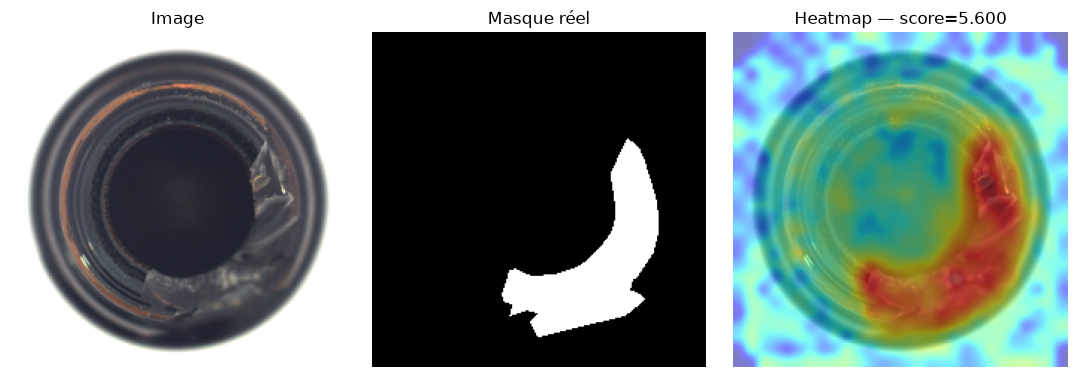

In [13]:
def visualize_prediction(path, category):
    score, hm = predict_one(path, category)
    mask=load_mask(path, category)
    with Image.open(path) as im:
        img=im.convert('RGB').resize((IMAGE_SIZE,IMAGE_SIZE))
    fig,axes=plt.subplots(1,3,figsize=(11,3.7))
    axes[0].imshow(img);axes[0].set_title('Image')
    axes[1].imshow(mask,cmap='gray',vmin=0,vmax=1);axes[1].set_title('Masque réel')
    axes[2].imshow(img);axes[2].imshow(hm,cmap='jet',alpha=0.52);axes[2].set_title(f'Heatmap — score={score:.3f}')
    for a in axes: a.axis('off')
    fig.tight_layout()
    return fig

cat='bottle'
example_defect=next((p for p in SPLITS[cat]['target_test'] if p.parent.name!='good'),None)
if example_defect:
    fig=visualize_prediction(example_defect,cat)
    fig.savefig(OUTPUT_DIR/'figures'/f'{cat}_example_heatmap.png',dpi=140)
    plt.show()

## Phase C — Évaluation et validation scientifique

### Étape 12 — Mesurer AUROC image, AP, AUROC pixel et AU-PRO

**Attention :** le test est utilisé exclusivement pour mesurer les performances. Aucune sélection de seuil, de coreset ou d'hyperparamètres n'est effectuée à partir de ses étiquettes. Pour le calcul de l’AU-PRO, nous intégrons la PRO jusqu’à FPR = 0,30 et normalisons par 0,30 ; la formule et le post-traitement peuvent différer de ceux d’une publication ou d’une bibliothèque donnée.

In [19]:
def compute_aupro(gt_masks, pred_maps, fpr_limit=0.30, thresholds_count=150):
    # gt_masks: [N,H,W] binaire ; pred_maps: [N,H,W] continu.
    gt=np.asarray(gt_masks,dtype=bool)
    scores=np.asarray(pred_maps,dtype=np.float32)
    negatives=(~gt).sum()
    if negatives==0: return float('nan')
    components=[]
    for i in range(len(gt)):
        labeled=label(gt[i],connectivity=2)
        for r in regionprops(labeled):
            coords=r.coords
            components.append((i,coords[:,0],coords[:,1]))
    if not components: return float('nan')
    # FPR croissant quand le seuil décroît.
    thresholds=np.linspace(float(scores.max())+1e-6,float(scores.min())-1e-6,thresholds_count)
    fprs=[0.0]; pros=[0.0]
    for th in thresholds:
        predicted=scores>=th
        fpr=float((predicted & (~gt)).sum()/negatives)
        pro=float(np.mean([predicted[i,ys,xs].mean() for i,ys,xs in components]))
        fprs.append(fpr);pros.append(pro)
        if fpr>=fpr_limit: break
    x=np.array(fprs);y=np.array(pros)
    order=np.argsort(x)
    x=x[order];y=y[order]
    # Les FPR peuvent être égaux : garder la plus grande PRO de chaque abscisse.
    uniq=np.unique(x)
    yy=np.array([y[x==u].max() for u in uniq])
    if uniq[-1]<fpr_limit:
        uniq=np.append(uniq,fpr_limit); yy=np.append(yy,yy[-1])
    grid=np.unique(np.concatenate(([0.0,fpr_limit],uniq[(uniq>0)&(uniq<fpr_limit)])))
    return float(np.trapezoid(np.interp(grid, uniq, yy), grid) / fpr_limit)

def evaluate_category(category):
    test_paths=SPLITS[category]['target_test']
    labels=[];image_scores=[];masks=[];maps=[]
    for p in tqdm(test_paths,desc=f'Évaluation {category}'):
        score, hm = predict_one(p,category)
        labels.append(int(p.parent.name!='good'))
        image_scores.append(score)
        masks.append(load_mask(p,category))
        maps.append(hm)
    labels=np.array(labels)
    masks=np.stack(masks)
    maps=np.stack(maps)
    return {
        'category':category,
        'n_test':len(labels),
        'image_AUROC':float(roc_auc_score(labels,image_scores)) if len(set(labels))==2 else float('nan'),
        'image_AP':float(average_precision_score(labels,image_scores)) if len(set(labels))==2 else float('nan'),
        'pixel_AUROC':float(roc_auc_score(masks.ravel(),maps.ravel())) if len(np.unique(masks))==2 else float('nan'),
        'pixel_AUPRO':compute_aupro(masks,maps),
    }

RESULTS=[]
for cat in CFG['categories']:
    started=time.perf_counter()
    result=evaluate_category(cat)
    result['eval_seconds']=round(time.perf_counter()-started,1)
    RESULTS.append(result)
    # Reprendre le run de la catégorie, sans créer de doublon.
    with mlflow.start_run(run_id=RUN_IDS[cat]):
        mlflow.log_metrics({k:float(v) for k,v in result.items()
                            if k!='category' and isinstance(v,(int,float)) and np.isfinite(v)})
RESULTS_DF=pd.DataFrame(RESULTS)
display(RESULTS_DF)
RESULTS_DF.to_csv(OUTPUT_DIR/'metrics'/'baseline_results.csv',index=False)


Évaluation bottle:   0%|          | 0/83 [00:00<?, ?it/s]

🏃 View run baseline_bottle at: http://mlflow:5000/#/experiments/1/runs/49b1ab990991446cb02e8d90cfb52f83
🧪 View experiment at: http://mlflow:5000/#/experiments/1


Évaluation carpet:   0%|          | 0/117 [00:00<?, ?it/s]

🏃 View run baseline_carpet at: http://mlflow:5000/#/experiments/1/runs/b8c873437b254bb9be1bab811cde528e
🧪 View experiment at: http://mlflow:5000/#/experiments/1


Évaluation metal_nut:   0%|          | 0/115 [00:00<?, ?it/s]

🏃 View run baseline_metal_nut at: http://mlflow:5000/#/experiments/1/runs/cd587e25d4c043e597ba8e4ed44de586
🧪 View experiment at: http://mlflow:5000/#/experiments/1


,category,n_test,image_AUROC,image_AP,pixel_AUROC,pixel_AUPRO,eval_seconds
0,bottle,83,0.976190,0.991321,0.975430,0.941963,10.3
1,carpet,117,0.908106,0.970751,0.978603,0.924616,18.6
2,metal_nut,115,0.829423,0.952440,0.905354,0.840383,14.7


### Étape 13 — Comparaison des trois catégories

,image_AUROC,image_AP,pixel_AUROC,pixel_AUPRO,eval_seconds
category,,,,,
bottle,0.9762,0.9913,0.9754,0.9420,10.3
carpet,0.9081,0.9708,0.9786,0.9246,18.6
metal_nut,0.8294,0.9524,0.9054,0.8404,14.7


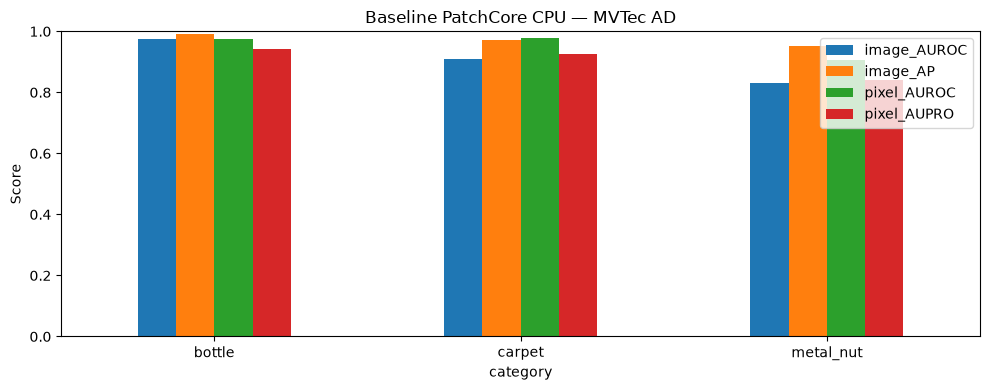

In [20]:
display(RESULTS_DF.set_index('category')[['image_AUROC','image_AP','pixel_AUROC','pixel_AUPRO','eval_seconds']].round(4))
ax=RESULTS_DF.set_index('category')[['image_AUROC','image_AP','pixel_AUROC','pixel_AUPRO']].plot(kind='bar',figsize=(10,4),ylim=(0,1),rot=0)
ax.set_title('Baseline PatchCore CPU — MVTec AD');ax.set_ylabel('Score');plt.tight_layout()
plt.savefig(OUTPUT_DIR/'figures'/'baseline_metrics.png',dpi=140)
plt.show()

### Étape 14 — Comparaison aux résultats publiés (discussion, sans faux ±1 point)

**À compléter après les exécutions :**

| Élément | Prototype local | Référence PatchCore |
|---|---|---|
| Backbone | ResNet-18, layer2/layer3 | WideResNet-50-2, layer2/layer3 (configuration usuelle) |
| Résolution | 224×224 | À relever dans l'article / l'implémentation retenue |
| Images normales | Sous-ensemble CPU | Ensemble d'entraînement selon protocole |
| Coreset | Glouton approximatif, 256 patchs | Ratio, stratégie et taille à documenter |
| Prétraitement / score / AU-PRO | Implémentation du notebook | À harmoniser avant comparaison |

**Conclusion provisoire :** les mesures de ce notebook servent de **baseline de développement CPU**. Le critère de reproduction à ±1 point ne peut être évalué honnêtement qu'avec un protocole expérimental comparable.

### Étape 15 — Sauvegarde des résultats et artefacts MLflow

Les runs MLflow ont été créés à l’étape 9 et complétés par les métriques à l’étape 12. Ici, nous ajoutons le tableau récapitulatif, les figures et le résumé JSON aux mêmes runs. Dans Docker, ouvrir http://localhost:5000 pour les consulter.


In [21]:
metrics_dir = OUTPUT_DIR / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)

csv_path = metrics_dir / "baseline_results.csv"

RESULTS_DF = pd.DataFrame(RESULTS)
RESULTS_DF.to_csv(csv_path, index=False)

print("CSV créé :", csv_path)
print("Nombre de résultats :", len(RESULTS_DF))

display(RESULTS_DF)

CSV créé : /workspace/notebooks/artifacts_baseline/metrics/baseline_results.csv
Nombre de résultats : 3


,category,n_test,image_AUROC,image_AP,pixel_AUROC,pixel_AUPRO,eval_seconds
0,bottle,83,0.976190,0.991321,0.975430,0.941963,10.3
1,carpet,117,0.908106,0.970751,0.978603,0.924616,18.6
2,metal_nut,115,0.829423,0.952440,0.905354,0.840383,14.7


In [22]:
SUMMARY = {'config':CFG,'versions':VERSIONS,'results':RESULTS,'bank_info':BANK_INFO,'dataset_root':str(MVTEC_ROOT)}
summary_path = OUTPUT_DIR/'metrics'/'run_summary.json'
summary_path.write_text(json.dumps(SUMMARY,indent=2),encoding='utf-8')
for cat in CFG['categories']:
    with mlflow.start_run(run_id=RUN_IDS[cat]):
        mlflow.log_artifact(str(summary_path), artifact_path='reports')
        mlflow.log_artifact(str(OUTPUT_DIR/'metrics'/'baseline_results.csv'), artifact_path='reports')
        figure_path = OUTPUT_DIR/'figures'/f'{cat}_example_heatmap.png'
        if figure_path.exists():
            mlflow.log_artifact(str(figure_path), artifact_path='figures')
print('Résultats et expériences MLflow sauvegardés :', MLFLOW_URI)


🏃 View run baseline_bottle at: http://mlflow:5000/#/experiments/1/runs/49b1ab990991446cb02e8d90cfb52f83
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run baseline_carpet at: http://mlflow:5000/#/experiments/1/runs/b8c873437b254bb9be1bab811cde528e
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run baseline_metal_nut at: http://mlflow:5000/#/experiments/1/runs/cd587e25d4c043e597ba8e4ed44de586
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Résultats et expériences MLflow sauvegardés : http://mlflow:5000


### Étape 16 — Checklist finale et passage vers les décalages d’éclairage

In [23]:
assert len(SPLITS)==3
assert len(BANKS)==3
assert all(len(BANKS[c])>0 for c in CFG['categories'])
assert all((OUTPUT_DIR/'splits'/f'{c}_splits.json').exists() for c in CFG['categories'])
assert (OUTPUT_DIR/'metrics'/'baseline_results.csv').exists()
assert (CONFIG_PATH).exists()
print('✅ Trois catégories préparées et évaluées')
print('✅ Splits vérifiés, originaux inchangés')
print('✅ Banques, configuration, métriques et figures sauvegardées')
print('➡️ Prochain notebook : 02_lighting_shifts_diagnostic.ipynb')

✅ Trois catégories préparées et évaluées
✅ Splits vérifiés, originaux inchangés
✅ Banques, configuration, métriques et figures sauvegardées
➡️ Prochain notebook : 02_lighting_shifts_diagnostic.ipynb
